# Computer Vision Laboratory
## Experiment 5: Feature Extraction using SIFT
**Student Name:** YASHASWINI B SURESH  

**USN:** 1RUA24CSE0548

**Date:** 03-11-2026

### 1. Aim
To implement the Scale-Invariant Feature Transform (SIFT) for detecting keypoints and extracting local feature descriptors from an image, and to visualize the detected keypoints.

### 2. Software Requirements
Python 3.x, OpenCV (≥ 4.4 for `cv2.SIFT_create`), NumPy, Matplotlib, scikit-image

`pip install opencv-python numpy matplotlib scikit-image`

### 3. Theory (short)
SIFT stages: scale-space construction → DoG scale space → keypoint localisation → orientation assignment → descriptor generation (128-D vector per keypoint).

In [1]:
pip install opencv-python numpy matplotlib scikit-image

### 4. Implementation: Keypoint Detection and Descriptor Extraction

Number of keypoints: 791
Descriptor shape: (791, 128)
Descriptor length: 128


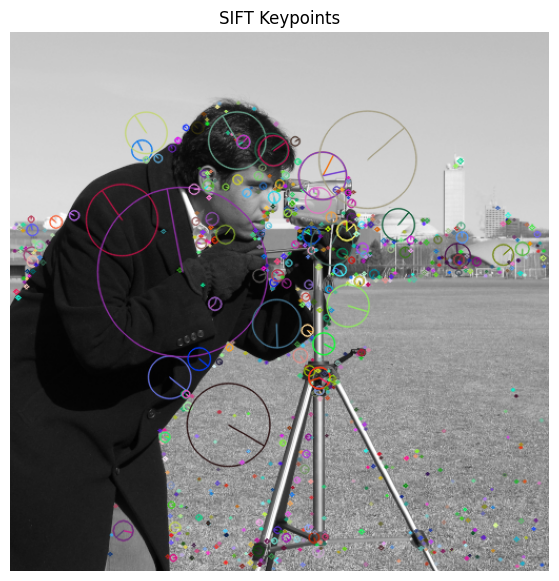

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Load grayscale image
image = data.camera().astype("uint8")

# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and compute descriptors
keypoints, descriptors = sift.detectAndCompute(image, None)

# Draw keypoints
output = cv2.drawKeypoints(image, keypoints, None,
                           flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

print("Number of keypoints:", len(keypoints))
if descriptors is not None:
    print("Descriptor shape:", descriptors.shape)
    print("Descriptor length:", descriptors.shape[1])

plt.figure(figsize=(10, 7))
plt.imshow(output, cmap="gray")
plt.title("SIFT Keypoints")
plt.axis("off")
plt.show()

### 5. Student Task 1 – Record the number of keypoints

In [3]:
n_orig = len(keypoints)
print("Keypoints detected in original image:", n_orig)

Keypoints detected in original image: 791


**Result (Task 1):** SIFT detected **791 keypoints** in the original `camera` image (count may differ slightly with other OpenCV versions).

### 6. Student Task 2 – Rotate the image by 30° and compare keypoints

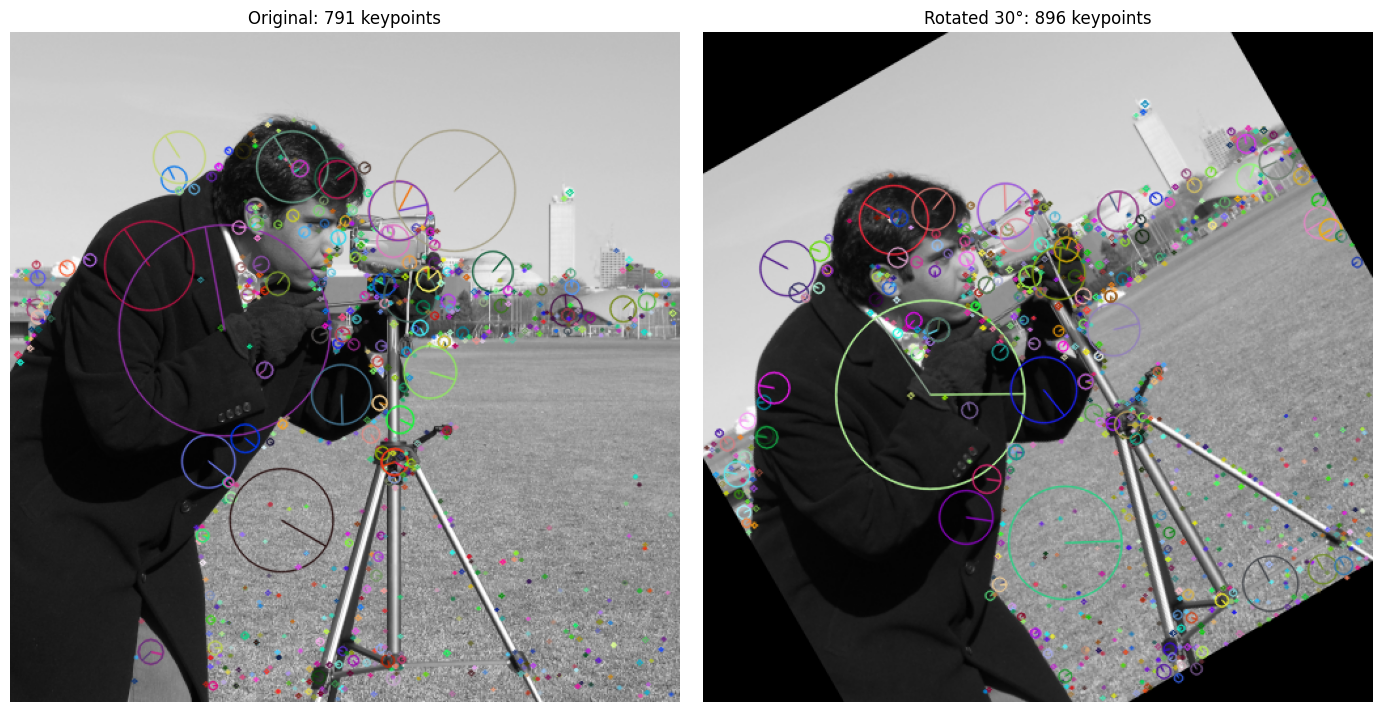

Original keypoints: 791
Rotated (30°) keypoints: 896


In [4]:
h, w = image.shape
center = (w // 2, h // 2)
M30 = cv2.getRotationMatrix2D(center, 30, 1.0)
rot30 = cv2.warpAffine(image, M30, (w, h))

kp_r, des_r = sift.detectAndCompute(rot30, None)
out_r = cv2.drawKeypoints(rot30, kp_r, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(output, cmap="gray"); ax[0].set_title(f"Original: {len(keypoints)} keypoints"); ax[0].axis("off")
ax[1].imshow(out_r, cmap="gray"); ax[1].set_title(f"Rotated 30°: {len(kp_r)} keypoints"); ax[1].axis("off")
plt.tight_layout(); plt.show()

print("Original keypoints:", len(keypoints))
print("Rotated (30°) keypoints:", len(kp_r))

**Observation (Task 2):** The rotated image gives a similar number of keypoints (about 896 vs 791). The keypoints sit on the same physical structures (camera, tripod, face, building edges) but their orientation arrows are rotated by about 30°. The small difference comes from the black corners created by the rotation (extra corner/border keypoints) and interpolation. This shows SIFT is rotation invariant.

### 7. Student Task 3 – Change the image scale

Scale  0.5: image size (256, 256), keypoints = 241
Scale 0.75: image size (384, 384), keypoints = 493
Scale  1.0: image size (512, 512), keypoints = 791
Scale  1.5: image size (768, 768), keypoints = 2304


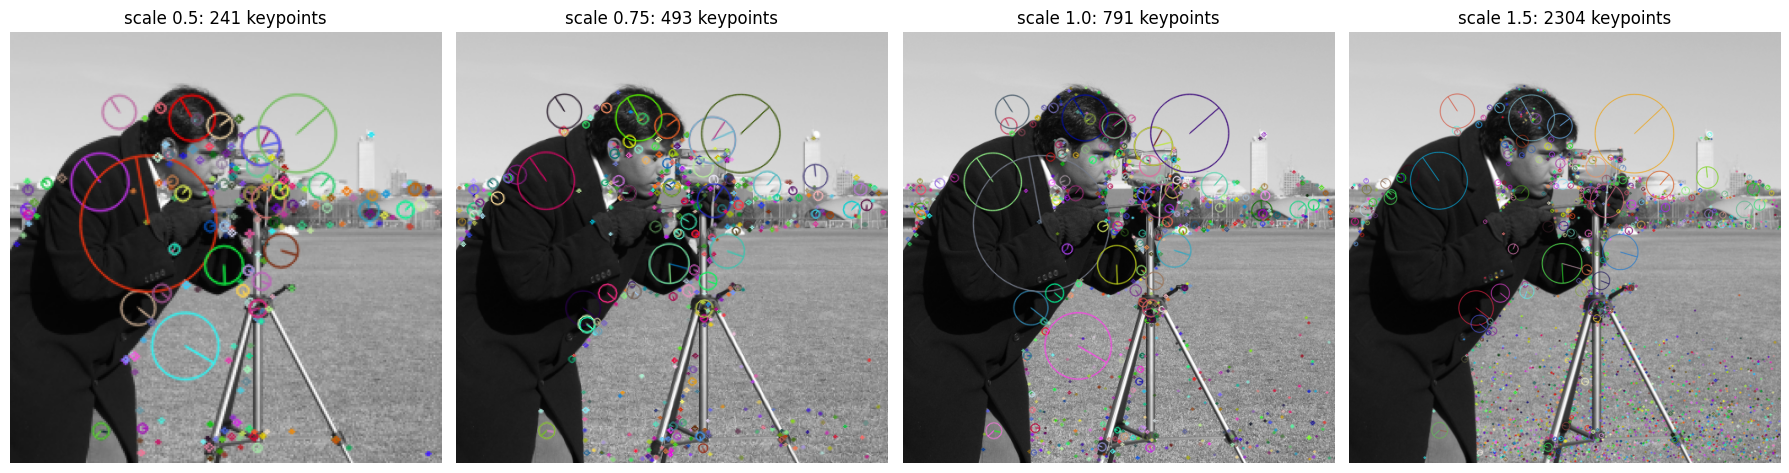

In [5]:
scales = [0.5, 0.75, 1.0, 1.5]
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
for a, s in zip(ax, scales):
    img_s = cv2.resize(image, None, fx=s, fy=s, interpolation=cv2.INTER_LINEAR)
    kp_s, des_s = sift.detectAndCompute(img_s, None)
    vis = cv2.drawKeypoints(img_s, kp_s, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    a.imshow(vis, cmap="gray"); a.set_title(f"scale {s}: {len(kp_s)} keypoints"); a.axis("off")
    print(f"Scale {s:4}: image size {img_s.shape}, keypoints = {len(kp_s)}")
plt.tight_layout(); plt.show()

**Observation (Task 3):** Distinctive features are still detected at every scale (0.5× → 241, 0.75× → 493, 1.0× → 791, 1.5× → 2304 keypoints). The *count* changes because a smaller image has fewer pixels/less detail and a larger image exposes more fine structure, but the same major structures (face, camera, tripod, building) keep getting detected. This is scale invariance from the DoG scale-space.

### 8. Student Task 4 – Verify each keypoint has a 128-D descriptor

In [6]:
print("Number of keypoints :", len(keypoints))
print("Descriptor matrix    :", descriptors.shape)
assert descriptors.shape[0] == len(keypoints)
assert descriptors.shape[1] == 128
print("Every keypoint has a 128-dimensional descriptor ✔")
print("\nFirst keypoint: pt =", np.round(keypoints[0].pt, 1),
      "size =", round(keypoints[0].size, 2), "angle =", round(keypoints[0].angle, 1))
print("First descriptor (first 16 values):", descriptors[0][:16])

Number of keypoints : 791
Descriptor matrix    : (791, 128)
Every keypoint has a 128-dimensional descriptor ✔

First keypoint: pt = [  3.9 185.4] size = 2.64 angle = 271.9
First descriptor (first 16 values): [ 5.  1.  0.  1.  1.  0.  0.  0. 52.  1.  0.  0.  1.  0.  0.  0.]


### 9. Student Task 5 – Feature matching between two related images (rotated by 25°)

Keypoints in image 1: 791
Keypoints in image 2: 866
Good matches: 476


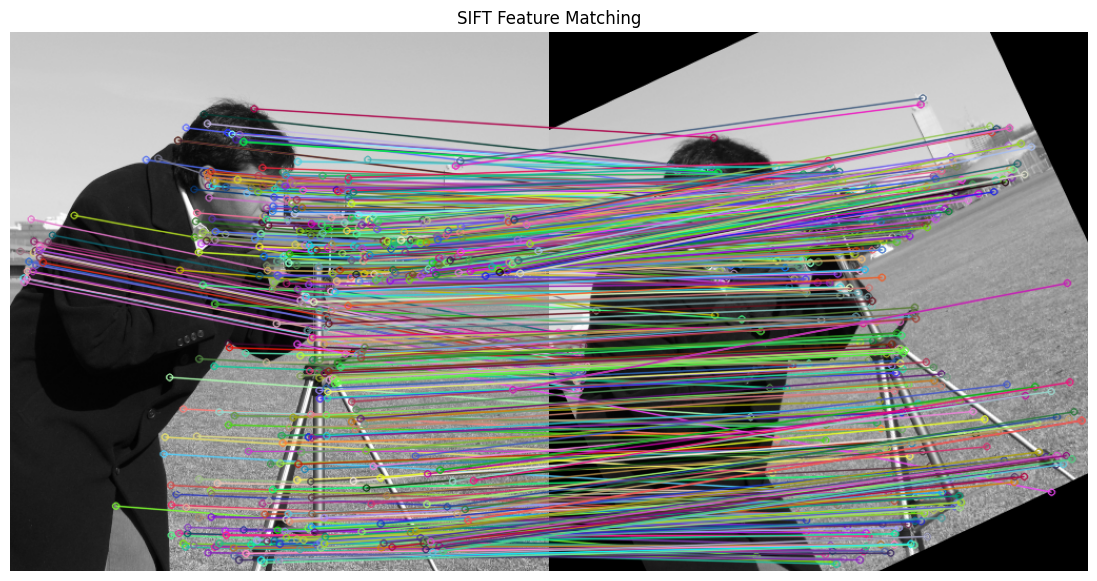

In [7]:
img1 = data.camera().astype("uint8")

h, w = img1.shape
M = cv2.getRotationMatrix2D((w // 2, h // 2), 25, 1.0)
img2 = cv2.warpAffine(img1, M, (w, h))

sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

# Brute-Force matcher using L2 distance
bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.knnMatch(des1, des2, k=2)

# Lowe ratio test
good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

result = cv2.drawMatches(img1, kp1, img2, kp2, good_matches, None,
                         flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

print("Keypoints in image 1:", len(kp1))
print("Keypoints in image 2:", len(kp2))
print("Good matches:", len(good_matches))

plt.figure(figsize=(14, 7))
plt.imshow(result, cmap="gray")
plt.title("SIFT Feature Matching")
plt.axis("off")
plt.show()

**Result (Task 5):** Image 1 has 791 keypoints, the rotated image has 866 keypoints, and **476 good matches** survive Lowe's ratio test (0.75). The match lines connect the same physical points in both images, even though one is rotated by 25°.

### 10. Extra: matching with 30° rotation (to compare with Task 2)

In [8]:
kp_a, des_a = sift.detectAndCompute(image, None)
kp_b, des_b = sift.detectAndCompute(rot30, None)
mm = cv2.BFMatcher(cv2.NORM_L2).knnMatch(des_a, des_b, k=2)
good30 = [m for m, n in mm if m.distance < 0.75 * n.distance]
print("Good matches (original vs 30° rotated):", len(good30))

Good matches (original vs 30° rotated): 478


### 11. Observation Table

| Experiment | Keypoints | Remarks |
|---|---|---|
| Original image | 791 | Descriptor matrix 791 × 128 |
| Rotated 25° | 866 | 476 good matches with original |
| Rotated 30° | 896 | ≈ 478 good matches with original |
| Scale 0.5× | 241 | Fewer details, major features still detected |
| Scale 0.75× | 493 | Most structures preserved |
| Scale 1.5× | 2304 | More fine-scale keypoints found |

### 12. Student Task 6 – Why is SIFT better than comparing raw pixel values?
Raw pixel comparison changes completely if the image is rotated, scaled, shifted, or its brightness changes, and it compares every pixel individually (slow and noise-sensitive). SIFT instead:
- detects **distinctive keypoints** (not every pixel) using DoG scale space,
- gives each keypoint a **scale and orientation**, so the descriptor is scale and rotation invariant,
- uses **gradient histograms** (128-D descriptor), which are robust to illumination changes and small viewpoint changes or noise,
- allows reliable matching with L2 distance + Lowe's ratio test.

So the same physical point can still be matched after the image is rotated or resized, whereas raw pixels cannot.

### 13. Viva Questions with Answers
1. **What does SIFT stand for?** Scale-Invariant Feature Transform.
2. **What is a keypoint?** A distinctive, repeatable image location (blob/corner-like point) detected by SIFT, with position, scale and orientation.
3. **What is a descriptor?** A numerical vector describing the local appearance (gradient pattern) around a keypoint.
4. **Why scale space?** Objects appear at different sizes; searching features across many blur levels (scales) lets the same feature be detected regardless of size.
5. **Why DoG?** It efficiently approximates the scale-normalised LoG and is computed by simply subtracting adjacent Gaussian-blurred images; extrema of DoG are stable keypoints.
6. **How is orientation assigned?** A histogram of gradient orientations (weighted by magnitude) is built around the keypoint; the peak (dominant direction) becomes its orientation (peaks ≥ 80% can create extra keypoints).
7. **Standard descriptor size?** 128 values (4×4 spatial cells × 8 orientation bins).
8. **Why scale invariant?** Keypoints are found as extrema across scale in the DoG pyramid and the descriptor is computed at the detected scale.
9. **Why rotation invariant?** The descriptor is computed relative to the keypoint's dominant orientation.
10. **Distance measure?** Euclidean (L2) distance.
11. **Lowe's ratio test?** Accept a match only if distance to the best match < ratio (e.g., 0.75) × distance to the second-best match; removes ambiguous matches.
12. **Does SIFT produce 3-D points or depth?** No. It gives 2-D keypoints and descriptors only; 3-D/depth needs stereo or multi-view geometry.

### 14. Result
SIFT keypoints and 128-dimensional local feature descriptors were extracted successfully using OpenCV. The keypoints were visualised, the effect of rotation and scaling was studied, and descriptor matching with Lowe's ratio test demonstrated how SIFT can match corresponding features between related images.